# Problem

## Reversible relaxation and apparent venous volume from real brain MRI

Four asymmetric spin-echo acquisitions change tissue nulling while measuring dephasing. We reconstruct R2-prime and apparent deoxygenated venous blood volume (DBV), not a validated oxygenation map. The bound data are one subject from Stone & Blockley's 2017 study (DOI 10.1016/j.neuroimage.2016.11.057); this is not reproduction of its seven-subject statistical results.

There is **no independent physiological ground truth**. The separately executed original Octave function supplies method comparisons. Every result called *fresh* below is calculated now from public measured data using local source modules. After original-only screening exposed extreme oxygen ratios, the output scope and thresholds were frozen before extraction. Signed fits remain visible; no target-derived quality mask is used.

In [1]:
from pathlib import Path
import sys,time,json
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display,Markdown
root=Path.cwd()
if not (root/'src').is_dir(): root=root.parent
assert (root/'data/raw_data.npz').is_file()
sys.path.insert(0,str(root))
from src.preprocessing import load_observations,observation_mask,TAU,CONDITIONS
from src.physics_model import design_matrix,forward_log,oxygen_diagnostics
from src.solvers import reconstruct,fit_signals
from src.visualization import field_grid,rmse
v=load_observations(root/'data/raw_data.npz')
up=np.load(root/'notebooks/reference_outputs/upstream.npz',allow_pickle=False)
names=['csfnull','nonull','gmnull','wmnull']
original_r=np.stack([up[n+'_r2p'] for n in names])
original_d=np.stack([up[n+'_dbv'] for n in names])
plt.rcParams.update({'font.size':9,'figure.dpi':110})

# Data

The source documents Siemens Magnetom Verio 3 T acquisition, body transmit/32-channel head receive coils, 240 mm field of view, 64×64 matrix, fixed TE 74 ms/TR 3 s and 24 displacements from −28 to 64 ms. Nulling inversion times are CSF 1.21 s, GM 0.702 s and WM 0.511 s; no-null data omit inversion preparation.

The original files contain 40 partitions at 1.25 mm. This task averages each four adjacent partitions into ten 5 mm slabs, preserving all frames. This task preprocessing is not the author's complete FSL motion/smoothing/segmentation pipeline. The published data are labelled filtered; no stronger raw-k-space claim is made. Source README suggests summation whereas source averaging code divides by four: this intensity factor leaves both inferred targets invariant. That code's hardcoded 7.5 mm header conflicts with these 5 mm slabs and is not adopted.

The fixed public region uses a central ellipse, slabs 2–7 and measured spin-echo intensity above half the condition's 95th percentile, with every magnitude positive. It is neither a grey-matter segmentation nor a fitted-parameter positivity filter. Images use native array coordinates, with no claim of anatomical registration between acquisitions.

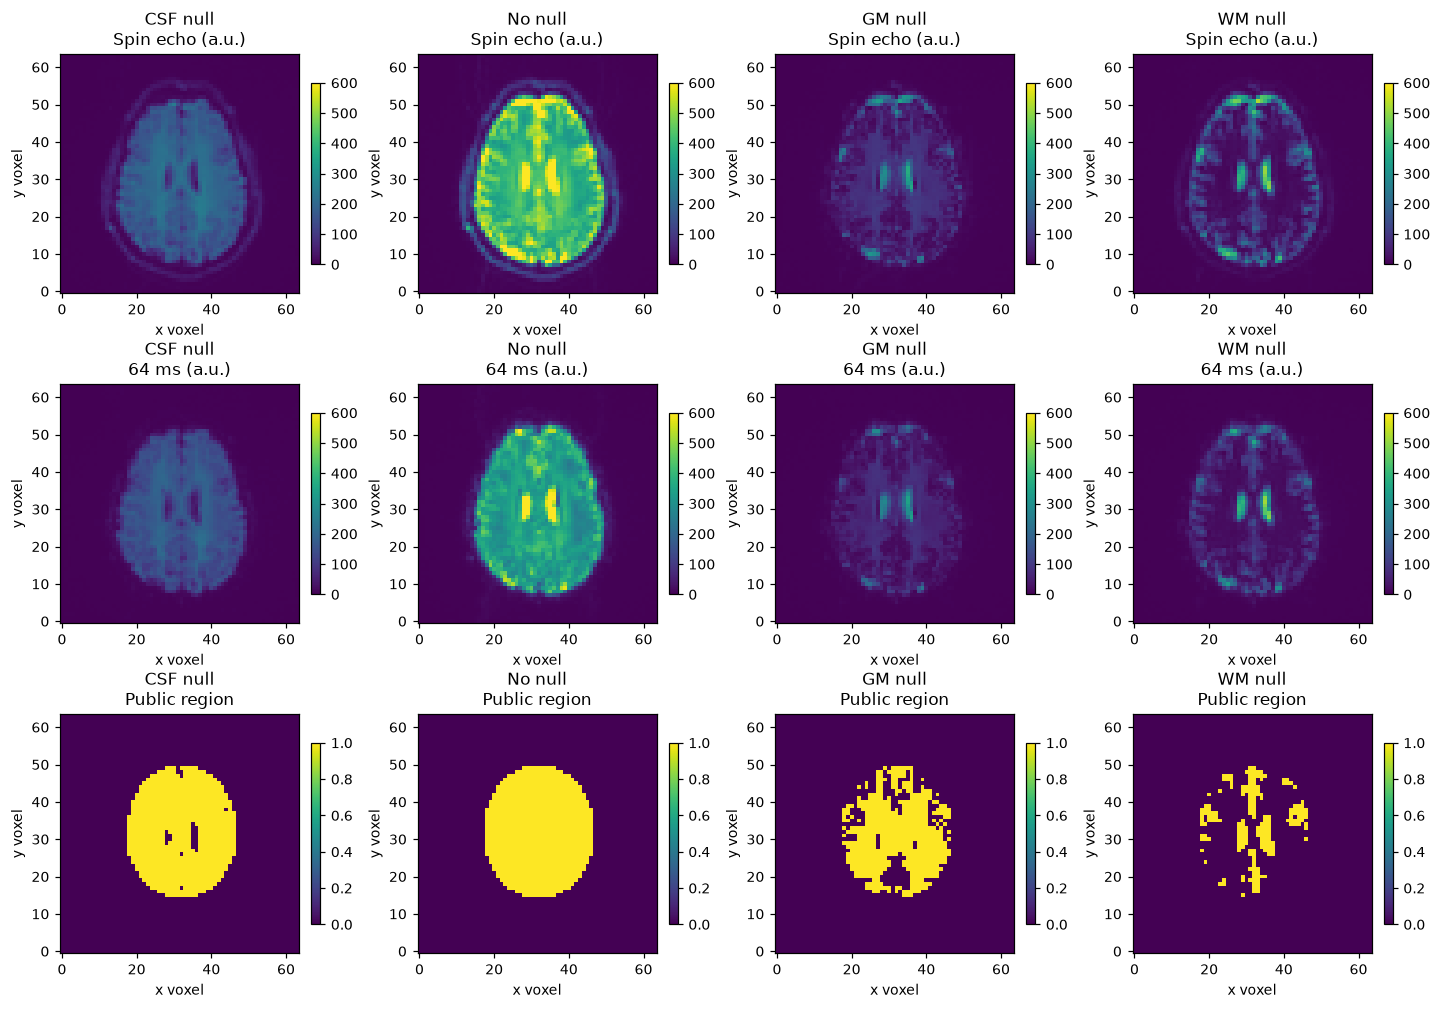

Condition | retained voxels | coverage of full grid | SE threshold (a.u.)
CSF null 4425 10.803% 95.50625
No null 4855 11.853% 261.375
GM null 3206 7.827% 50.375
WM null 1672 4.082% 85.50625


In [2]:
mask=observation_mask(v)
fig=field_grid([v[...,7],v[...,23],mask.astype(float)],['Spin echo (a.u.)','64 ms (a.u.)','Public region'],[(0,600),(0,600),(0,1)],slice_index=4)
plt.show()
print('Condition | retained voxels | coverage of full grid | SE threshold (a.u.)')
for c,label in enumerate(CONDITIONS):
    print(label,mask[c].sum(),f'{mask[c].mean():.3%}',.5*np.percentile(v[c,...,7],95))

# Physics

At the spin echo, the log amplitude is $a$. At sufficiently long positive displacement $\tau$, measured log magnitude is approximated by

$$\log S(0)=a,\qquad \log S(\tau)=a+v-\tau r+\epsilon(\tau).$$

$S$ is arbitrary-unit magnitude, $v$ is DBV fraction, $r$ is R2-prime in inverse seconds, and $\epsilon$ includes both measurement noise and model discrepancy. The fixed echo-time transverse relaxation factor is absorbed into $a$. The long-time slope identifies $r$; the small intercept difference from the spin echo identifies $v$. The asymptotic positive-time formula does not predict the supplied short/negative-time measurements, which are displayed as context.

The static-dephasing approximation omits diffusion narrowing and several tissue/vascular signal contributions. Incomplete suppression and macroscopic gradients can change apparent parameters. These effects, along with a noisy spin echo, make biological interpretation less secure than numerical agreement.

# Method

The selected original method is **unweighted** linear least squares on the spin echo and thirteen times 16–64 ms. With parameter vector $p=(v,r,a)^T$, a long-time row of design matrix $X$ is $(1,-\tau,1)$ and the spin-echo row is $(0,0,1)$. For selected log observations $y$, the local implementation solves

$$\widehat p=\operatorname*{arg\,min}_{p}\sum_j(X_jp-y_j)^2.$$

There are no regularizers, positivity constraints or iterative stopping decisions. A direct general linear decomposition implements the inverse. The original's log-zero convention is preserved for diagnostics, but the public region requires positive observations. The design has full rank only because of its spin-echo row.

The following cell actively fits **all four complete acquisitions**. It does not load a saved reconstruction as its result.

In [3]:
start=time.perf_counter()
fresh,diag=reconstruct(v)
elapsed=time.perf_counter()-start
p=diag['parameters'];r=p[...,1];d=p[...,0]
X,idx=design_matrix()
print(f'Fresh complete reconstruction: {elapsed:.4f} s; design rank {np.linalg.matrix_rank(X)}, condition number {np.linalg.cond(X):.2f}')
assert fresh['reconstruction'].shape==(1,4,64,64,10)
assert np.isfinite(fresh['reconstruction']).all() and np.isfinite(fresh['dbv']).all()

Fresh complete reconstruction: 0.0758 s; design rank 3, condition number 95.53


# Results

## Original execution versus fresh local reconstruction

The method reference is the original function executed in Octave 8.4 on these same averaged observations. It is not ground truth or a historical paper figure. The original and fresh fields below use the identical public region. Signed color scales expose negative fits; fixed display limits are for readability, and complete ranges and negative fractions are reported afterwards. Display clipping never changes evaluation arrays.

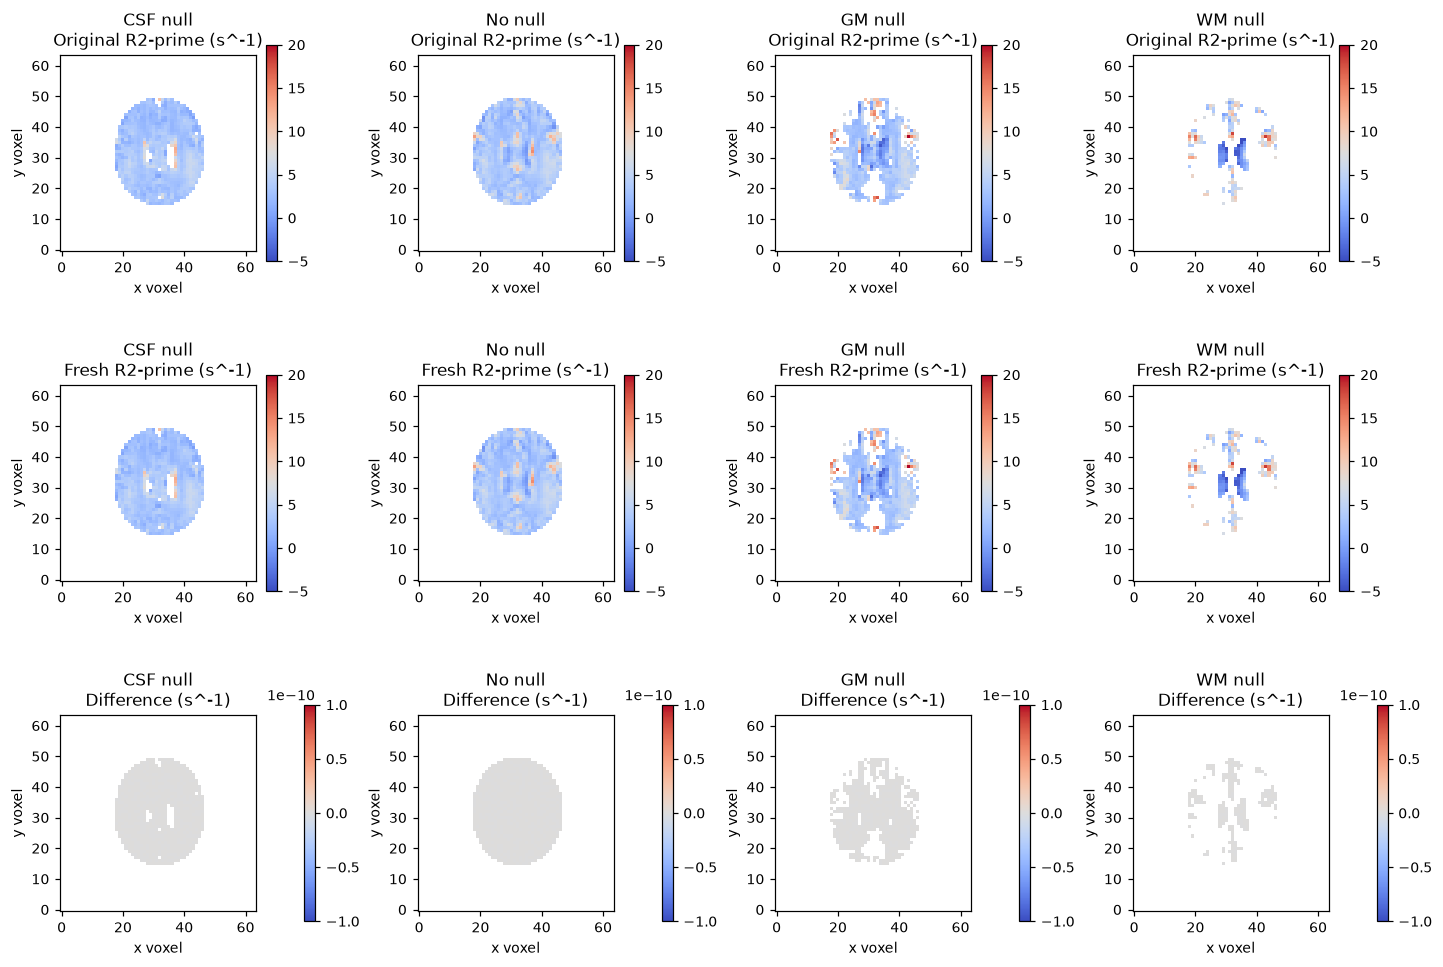

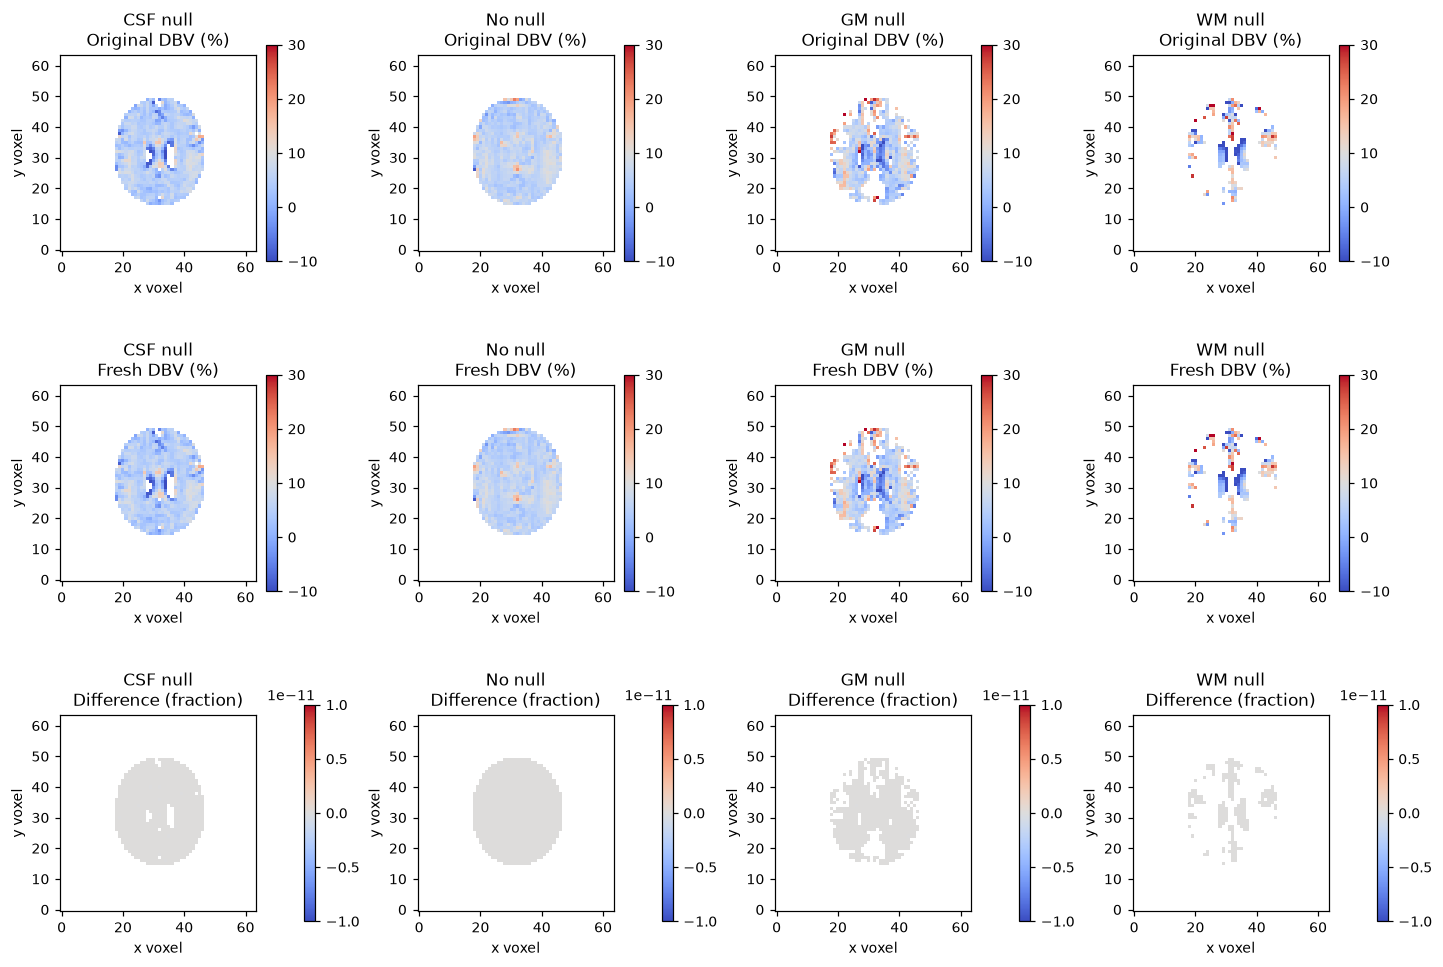

| Condition | R2-prime RMSE (s^-1) | DBV RMSE (fraction) | median log residual |
|---|---:|---:|---:|
|CSF null|2.358e-14|5.422e-15|0.01204|
|No null|2.570e-14|6.348e-15|0.01261|
|GM null|1.961e-14|4.817e-15|0.02766|
|WM null|2.312e-14|5.508e-15|0.02657|

In [4]:
shown=lambda a:np.where(mask,a,np.nan)
field_grid([shown(original_r),shown(r),shown(r-original_r)],['Original R2-prime (s^-1)','Fresh R2-prime (s^-1)','Difference (s^-1)'],[(-5,20),(-5,20),(-1e-10,1e-10)],cmap='coolwarm')
plt.show()
field_grid([shown(original_d)*100,shown(d)*100,shown(d-original_d)],['Original DBV (%)','Fresh DBV (%)','Difference (fraction)'],[(-10,30),(-10,30),(-1e-11,1e-11)],cmap='coolwarm')
plt.show()
rows=['| Condition | R2-prime RMSE (s^-1) | DBV RMSE (fraction) | median log residual |','|---|---:|---:|---:|']
for c,label in enumerate(CONDITIONS):
    m=mask[c]
    rows.append(f'|{label}|{rmse(r[c][m],original_r[c][m]):.3e}|{rmse(d[c][m],original_d[c][m]):.3e}|{np.median(diag["log_rmse"][c][m]):.5f}|')
display(Markdown('\n'.join(rows)))

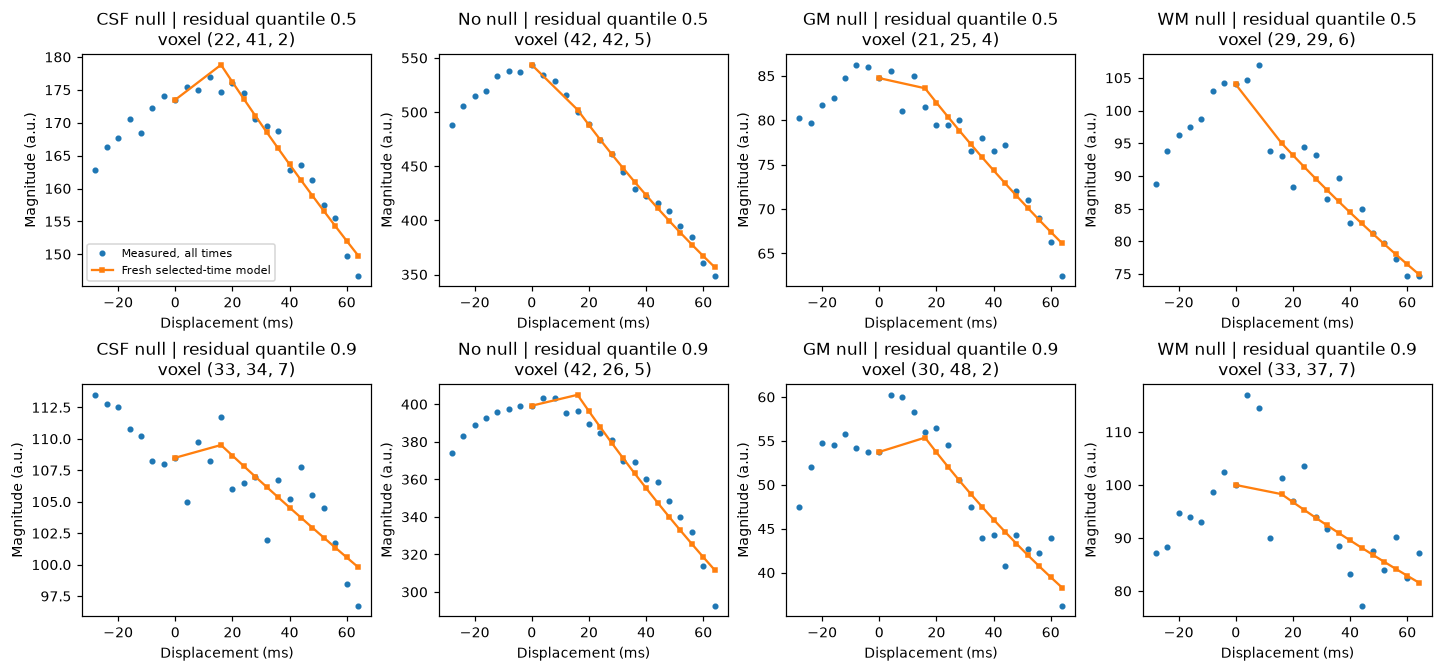

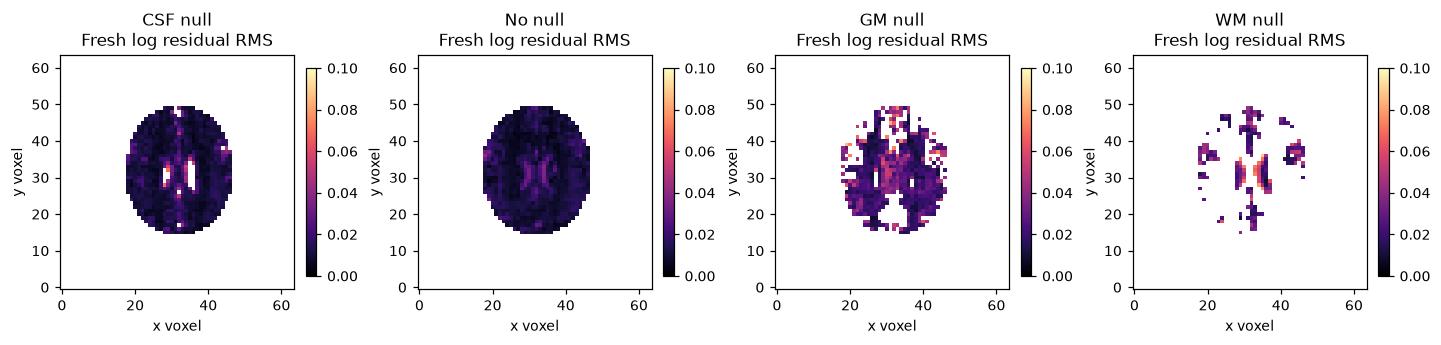

In [5]:
# Actual measured curves: one median-residual and one 90th-percentile-residual voxel per condition.
fig,axes=plt.subplots(2,4,figsize=(13,6),layout='constrained')
for c in range(4):
    coords=np.argwhere(mask[c]);errors=diag['log_rmse'][c][mask[c]]
    for row,quantile in enumerate([.5,.9]):
        location=tuple(int(a) for a in coords[np.argmin(np.abs(errors-np.quantile(errors,quantile)))])
        signal=v[(c,)+location];model=np.exp(forward_log(p[(c,)+location]))
        ax=axes[row,c];ax.plot(TAU*1000,signal,'o',ms=3,label='Measured, all times')
        ax.plot(TAU[idx]*1000,model,'s-',ms=3,label='Fresh selected-time model')
        ax.set_title(f'{CONDITIONS[c]} | residual quantile {quantile}\nvoxel {location}')
        ax.set_xlabel('Displacement (ms)');ax.set_ylabel('Magnitude (a.u.)')
axes[0,0].legend(fontsize=7);plt.show()
field_grid([shown(diag['log_rmse'])],['Fresh log residual RMS'],[(0,.10)],cmap='magma')
plt.show()

## Signed estimates and condition dependence

The four acquisitions are preserved as separate scientific comparison groups. Suppression changes both signal composition and signal-to-noise ratio. The central regions overlap in index space but are not anatomically registered tissue masks; differences below must not be called a causal voxelwise nulling effect or a grey-matter cohort statistic. The display histograms are accompanied by full extrema, so outliers are not silently discarded.

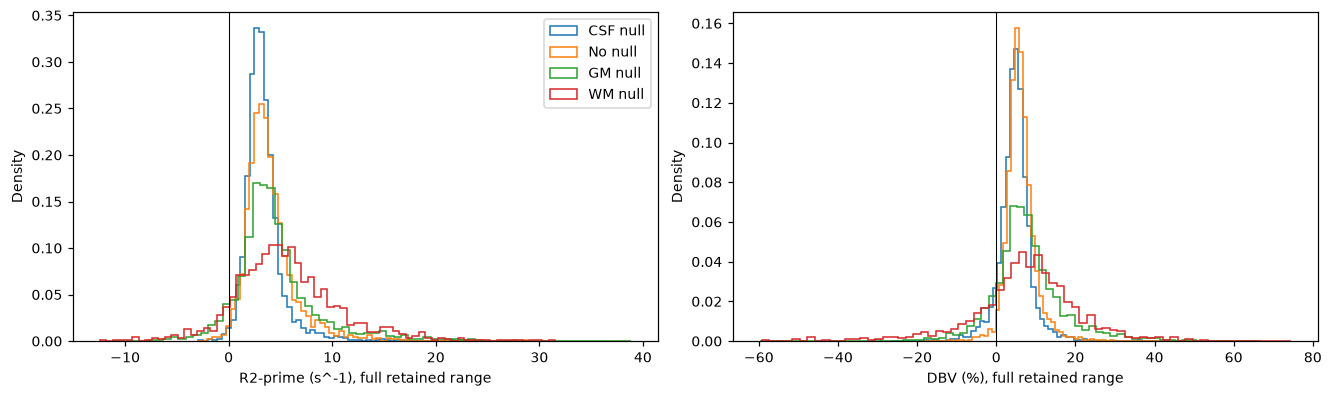

| Condition | R2-prime min/max | DBV min/max | Negative R2-prime | Negative DBV |
|---|---:|---:|---:|---:|
|CSF null|-2.942, 28.620|-0.2679, 0.4884|0.90%|8.86%|
|No null|-2.987, 28.800|-0.1815, 0.5174|1.15%|2.64%|
|GM null|-11.310, 38.866|-0.5980, 0.6681|7.08%|13.91%|
|WM null|-12.455, 31.540|-0.5920, 0.7449|9.15%|21.65%|

In [6]:
fig,axes=plt.subplots(1,2,figsize=(12,3.5),layout='constrained')
for c,label in enumerate(CONDITIONS):
    axes[0].hist(r[c][mask[c]],bins=70,histtype='step',density=True,label=label)
    axes[1].hist(100*d[c][mask[c]],bins=70,histtype='step',density=True,label=label)
axes[0].set_xlabel('R2-prime (s^-1), full retained range');axes[1].set_xlabel('DBV (%), full retained range')
for ax in axes:ax.set_ylabel('Density');ax.axvline(0,color='black',lw=.7)
axes[0].legend();plt.show()
rows=['| Condition | R2-prime min/max | DBV min/max | Negative R2-prime | Negative DBV |','|---|---:|---:|---:|---:|']
for c,label in enumerate(CONDITIONS):
    a=r[c][mask[c]];b=d[c][mask[c]]
    rows.append(f'|{label}|{a.min():.3f}, {a.max():.3f}|{b.min():.4f}, {b.max():.4f}|{np.mean(a<0):.2%}|{np.mean(b<0):.2%}|')
display(Markdown('\n'.join(rows)))

## Real-data fit-range sensitivity and labeled perturbation

The first comparison refits the same measured data with a later 23 ms cutoff (24–64 ms retained), testing sensitivity to the assumed asymptotic regime. It is an actual fresh alternative fit, not the benchmark estimator. The second experiment changes only measured spin-echo magnitudes by ±1%, a **synthetic sensitivity perturbation of real measurements**, not an additional acquisition. The public mask stays fixed to the original observations. Because the intercept separation is weak, this small amplitude shift changes DBV while leaving the long-time slope nearly unchanged.

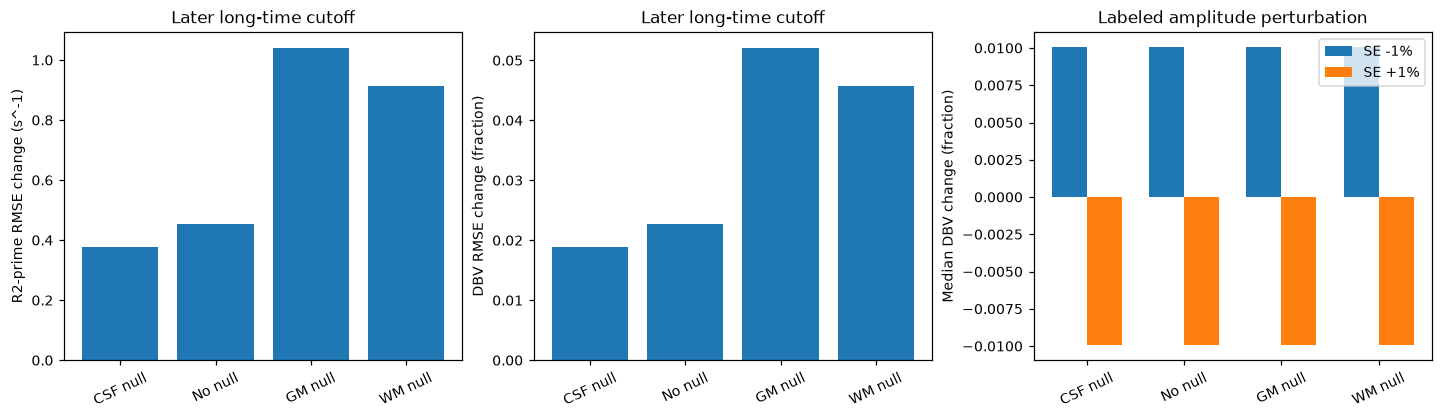

Expected amplitude-only DBV shifts: 0.01005033585350145 -0.009950330853168092
Maximum R2-prime change after 1% SE perturbation: 5.861977570020827e-14


In [7]:
late,_=fit_signals(v,cutoff=.023)
perturbed=[]
for factor in [.99,1.01]:
    altered=v.astype(np.float64).copy();altered[...,7]*=factor
    pp,_=fit_signals(altered);perturbed.append(pp)
fig,axes=plt.subplots(1,3,figsize=(13,3.7),layout='constrained')
positions=np.arange(4)
axes[0].bar(positions,[rmse(late[c,...,1][mask[c]],r[c][mask[c]]) for c in range(4)])
axes[1].bar(positions,[rmse(late[c,...,0][mask[c]],d[c][mask[c]]) for c in range(4)])
for offset,pp,label in [(-.18,perturbed[0],'SE -1%'),(.18,perturbed[1],'SE +1%')]:
    axes[2].bar(positions+offset,[np.median(pp[c,...,0][mask[c]]-d[c][mask[c]]) for c in range(4)],width=.36,label=label)
for ax in axes:ax.set_xticks(positions,CONDITIONS,rotation=25)
axes[0].set_ylabel('R2-prime RMSE change (s^-1)');axes[0].set_title('Later long-time cutoff')
axes[1].set_ylabel('DBV RMSE change (fraction)');axes[1].set_title('Later long-time cutoff')
axes[2].set_ylabel('Median DBV change (fraction)');axes[2].set_title('Labeled amplitude perturbation');axes[2].legend()
plt.show()
print('Expected amplitude-only DBV shifts:',-np.log(.99),-np.log(1.01))
print('Maximum R2-prime change after 1% SE perturbation:',max(np.max(np.abs(pp[...,1][mask]-r[mask])) for pp in perturbed))

## Why oxygenation is not a primary output

With assumed haematocrit $h=0.34$, gyromagnetic ratio $\gamma=26750$ rad/(s Gauss), field $B=30000$ Gauss, susceptibility difference $\Delta\chi=0.264\times10^{-6}$ and conversion factor $k=0.03$, the original derives

$$\mathrm{OEF}=\frac{r}{v\gamma(4/3)\pi\Delta\chi B h},\qquad [\mathrm{dHb}]=\frac{r}{v\gamma(4/3)\pi\Delta\chi B k}.$$

OEF is a fraction and dHb has units g/dL. These constants include physiological assumptions, not measured subject calibration. Division by small or negative DBV creates extreme or nonphysical ratios. The table reports every condition's extrema, nonfinite count, OEF fraction outside [0,1], and dHb fraction outside [0,15] g/dL. The latter interval is an explicit descriptive diagnostic screen, not a universal physiological standard or benchmark acceptance bound. The plot uses symmetric-log axes to retain extreme signed values. No ratio is labelled independent truth.

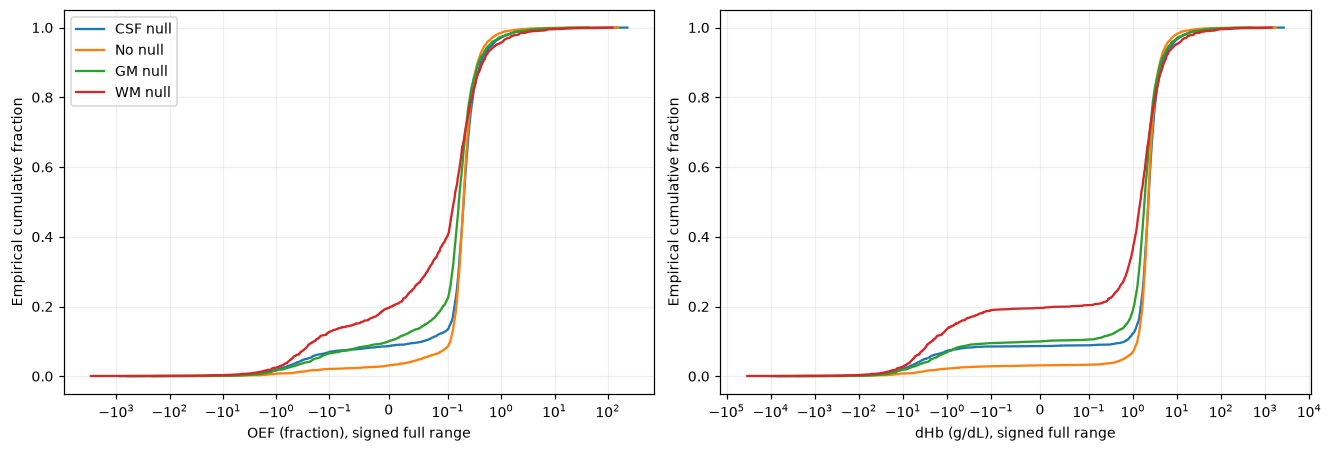

| Condition | OEF finite min/max | OEF nonfinite | OEF outside [0,1] | dHb finite min/max (g/dL) | dHb nonfinite | dHb outside [0,15] |
|---|---:|---:|---:|---:|---:|---:|
|CSF null|-888.23, 231.28|0|11.46%|-10066.65, 2621.20|0|10.55%|
|No null|-212.08, 153.69|0|4.57%|-2403.53, 1741.78|0|4.06%|
|GM null|-604.90, 44.00|0|12.57%|-6855.51, 498.70|0|12.10%|
|WM null|-2982.35, 122.19|0|23.80%|-33800.00, 1384.79|0|22.61%|

In [8]:
oef,dhb=oxygen_diagnostics(r,d)
rows=['| Condition | OEF finite min/max | OEF nonfinite | OEF outside [0,1] | dHb finite min/max (g/dL) | dHb nonfinite | dHb outside [0,15] |','|---|---:|---:|---:|---:|---:|---:|']
fig,axes=plt.subplots(1,2,figsize=(12,4),layout='constrained')
for c,label in enumerate(CONDITIONS):
    a=oef[c][mask[c]];b=dhb[c][mask[c]];af=a[np.isfinite(a)];bf=b[np.isfinite(b)]
    rows.append(f'|{label}|{af.min():.2f}, {af.max():.2f}|{np.sum(~np.isfinite(a))}|{np.mean((a<0)|(a>1)|~np.isfinite(a)):.2%}|{bf.min():.2f}, {bf.max():.2f}|{np.sum(~np.isfinite(b))}|{np.mean((b<0)|(b>15)|~np.isfinite(b)):.2%}|')
    axes[0].plot(np.sort(af),np.arange(1,len(af)+1)/len(af),label=label)
    axes[1].plot(np.sort(bf),np.arange(1,len(bf)+1)/len(bf),label=label)
for ax in axes:ax.set_xscale('symlog',linthresh=.1);ax.set_ylabel('Empirical cumulative fraction');ax.grid(alpha=.2)
axes[0].set_xlabel('OEF (fraction), signed full range');axes[1].set_xlabel('dHb (g/dL), signed full range');axes[0].legend()
plt.show();display(Markdown('\n'.join(rows)))
for c,n in enumerate(names):
    np.testing.assert_allclose(oef[c][mask[c]],up[n+'_oef'][mask[c]],atol=1e-5,rtol=1e-7)
    np.testing.assert_allclose(dhb[c][mask[c]],up[n+'_dhb'][mask[c]],atol=1e-4,rtol=1e-7)

# Conclusion

The active reconstruction reproduces the selected original linear inverse on all four measured acquisitions, with independent stage fixtures and analytic unit checks. This validates implementation fidelity, not physiological truth. R2-prime and apparent DBV retain signed failures; residuals, cutoff sensitivity and amplitude sensitivity expose limitations of the selected approximation.

The oxygen ratios are highly unstable at small DBV and can lie far outside plausible ranges. They are retained as explicit failure diagnostics and excluded from the primary output contract. This single-subject, native-grid benchmark does not reproduce registered tissue-group statistics, the author's full FSL preprocessing, or stable quantitative oxygenation recovery.